1) EQUAÇÃO DE DIFERENÇAS (1ª ordem)
  y[n] = 0.2 x[n] + 0.8 y[n-1]
  (convenção do roteiro: b0 = 0.2, a1 = -0.8)

2) FUNÇÃO DE TRANSFERÊNCIA
  H(z) = 0.2 / (1 - 0.8 z^-1) = 0.2 z / (z - 0.8)
  Ordem do filtro: 1 (número de polos)

3) RESPOSTA AO IMPULSO
  h[n] = 0.2 · 0.8^n · u[n]
  erro lfilter x teoria:        2.78e-17
  erro recursão manual x teoria: 2.78e-17
  h[n] > 0 para todo n (60 amostras)? True  -> resposta infinita (nunca se anula exatamente)
  |h[n]| < 1% de h[0] a partir de n = 21; < 0,1% a partir de n = 31
  soma de h[n] (ganho DC): teoria 1,0000 | 60 amostras = 1.0000

4-5) POLOS E ZEROS
  Polos: [0.8]  (|p| = 0.80)
  Zeros: z = 0 (de H(z) = 0,2 z/(z - 0,8): numerador de grau 1)

6-7) MAGNITUDE E FASE
  erro definição x scipy.freqz: 4.00e-16
  |H(1)| = 1.0000 | |H(-1)| = 0.1111 (-19.08 dB)
  corte -3 dB: 0.2241 rad (0.071π; 35.7 Hz)
  corte teórico arccos(1 - (1-α)²/(2α)) = 0.2241 rad
  Fase em ω = π/4: -52.48°
  Atraso de grupo: ω = 0 -> 4.000 amostras (= α/(1-α) = 4.00

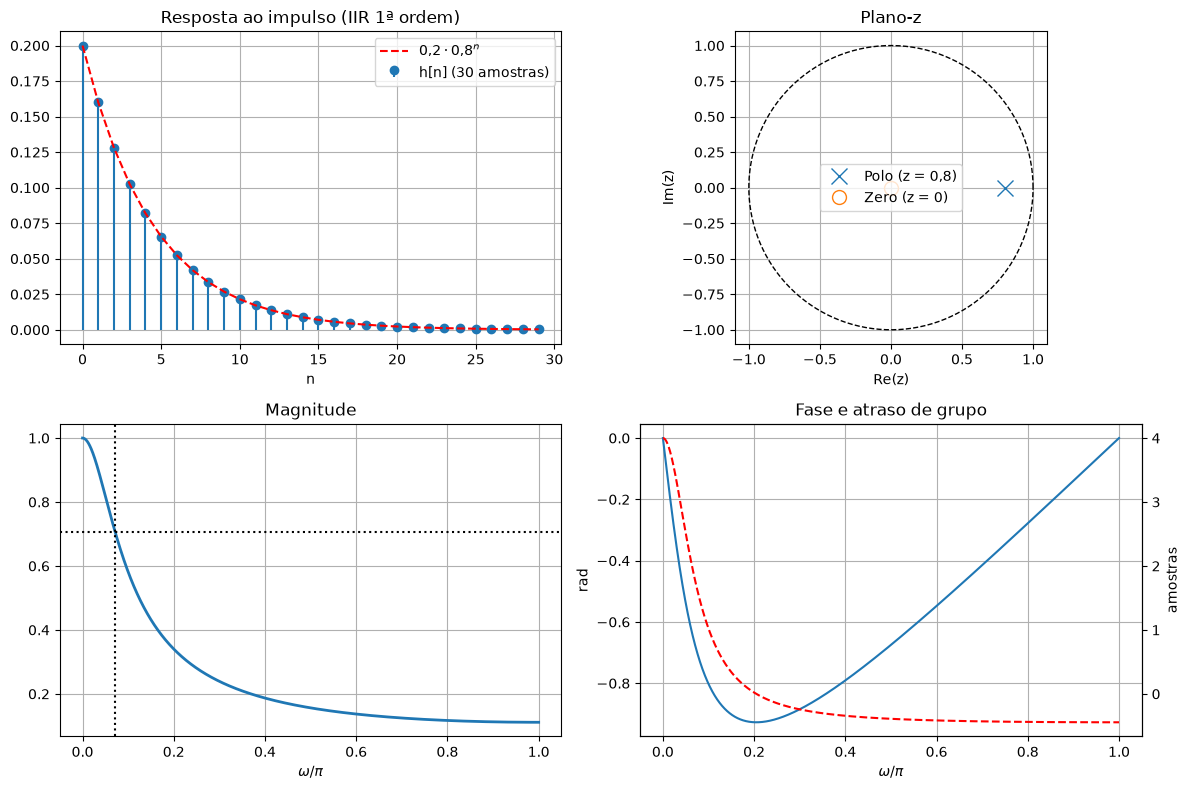

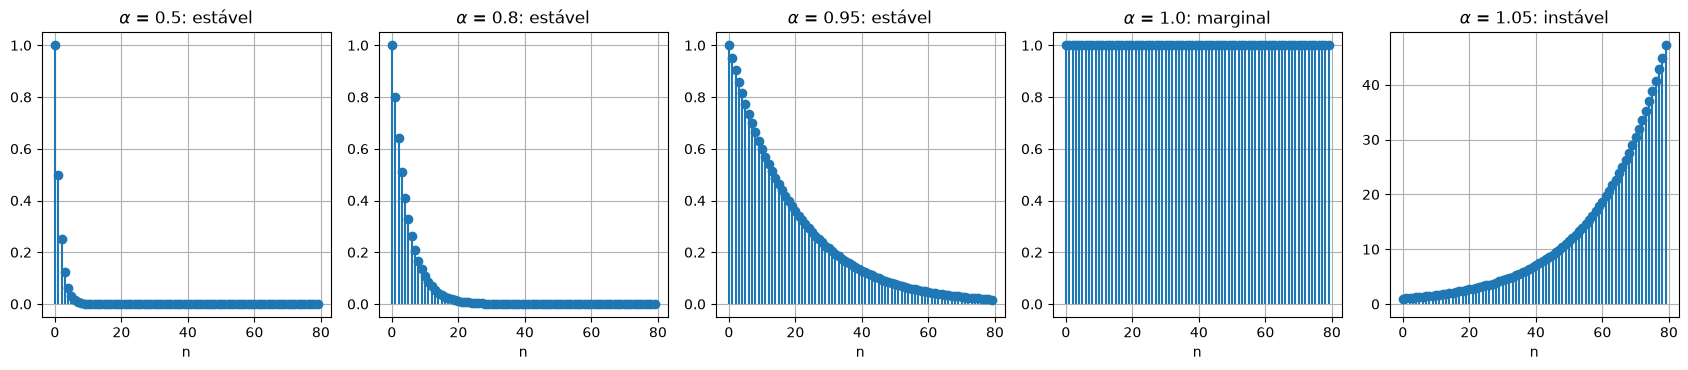

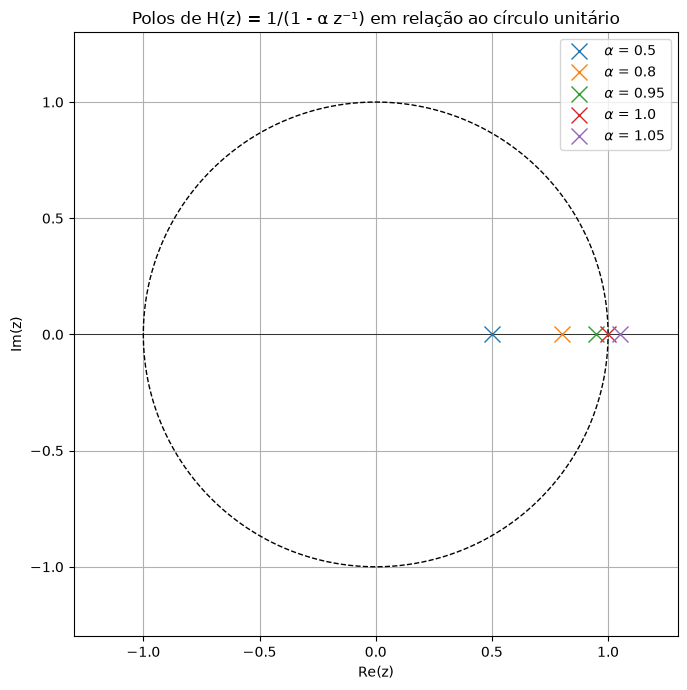

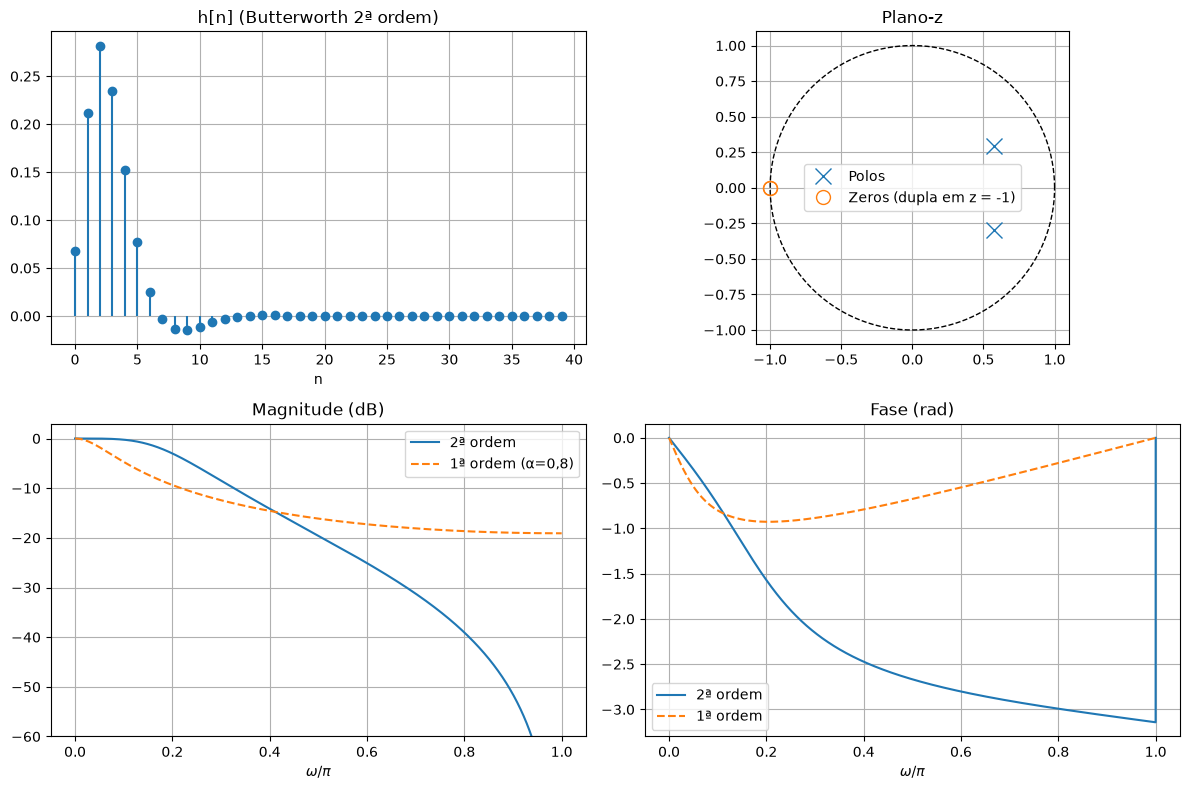

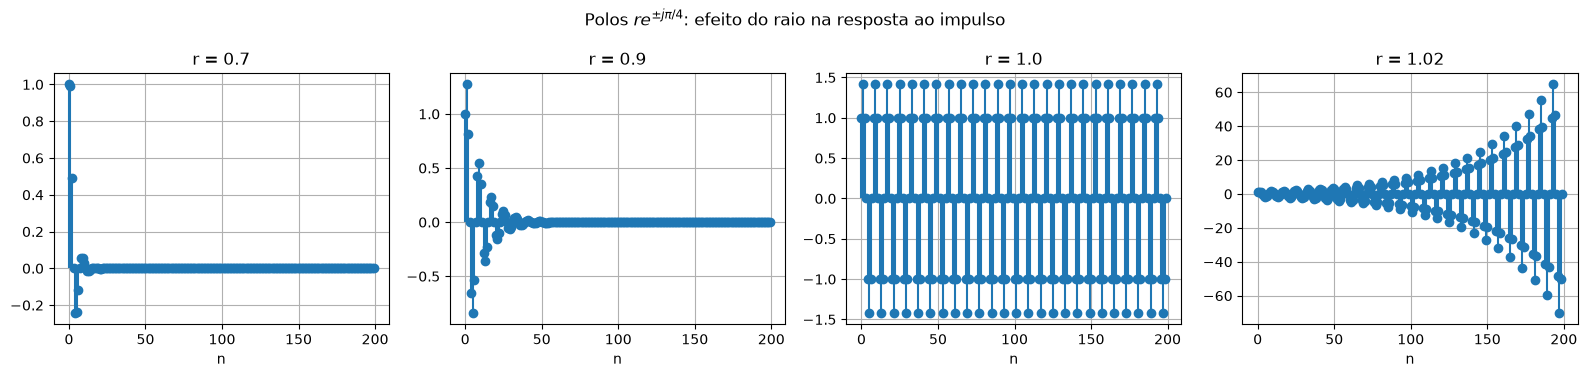

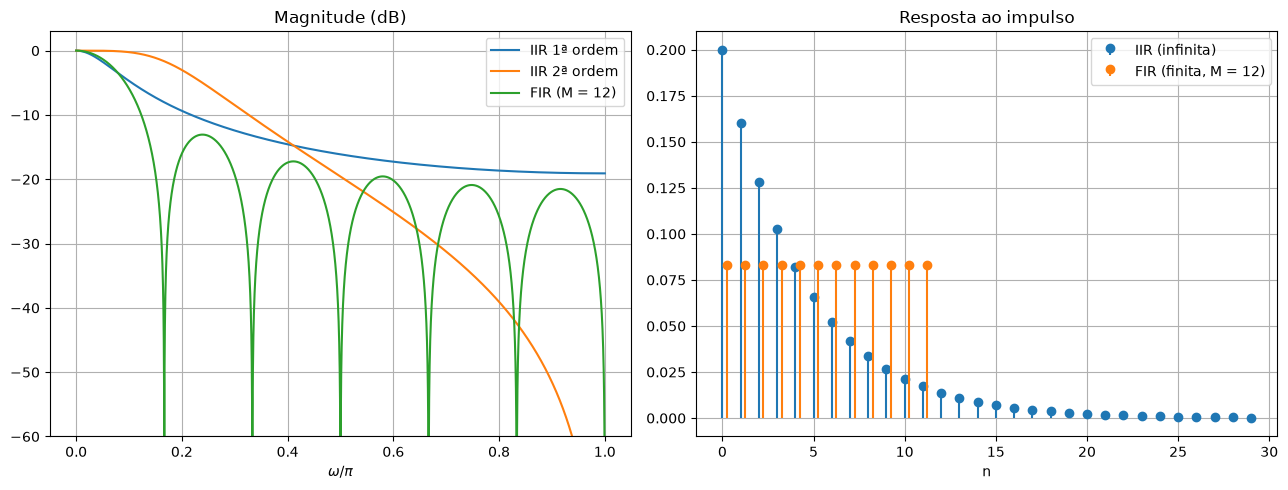


Simulação concluída!


In [1]:
"""
Roteiro de Filtros Digitais - Tópico 5: Filtros IIR

Convenção do roteiro:
    y[n] = sum_{k=0}^{M} b_k x[n-k] - sum_{k=1}^{N} a_k y[n-k]
    H(z) = (sum b_k z^-k) / (1 + sum a_k z^-k)
que coincide com a de scipy.signal (vetor a com a[0] = 1).

Filtro principal (1ª ordem, passa-baixas):
    y[n] = (1 - alfa) x[n] + alfa y[n-1]      (b0 = 1-alfa, a1 = -alfa)
    H(z) = (1 - alfa) / (1 - alfa z^-1),  polo em z = alfa

Investigação (9.2): 1) equação de diferenças, 2) função de transferência,
3) resposta ao impulso, 4) polos, 5) zeros, 6) magnitude, 7) fase,
8) estabilidade. Complementos: filtro de 2ª ordem (Butterworth) e
comparação de custo com um FIR de mesmo corte.

Convenção: ω em rad/amostra; eixo em Hz usa fs = 1000 Hz.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 1000.0
w = np.linspace(0, np.pi, 8001)
th = np.linspace(0, 2 * np.pi, 400)


# ============================================================
# FUNÇÕES AUXILIARES
# ============================================================

def iir_direto(b, a, x):
    """Recursão da equação de diferenças (a[0] = 1)."""
    y = np.zeros(len(x))
    for n in range(len(x)):
        acc = 0.0
        for k, bk in enumerate(b):
            if n - k >= 0:
                acc += bk * x[n - k]
        for k in range(1, len(a)):
            if n - k >= 0:
                acc -= a[k] * y[n - k]
        y[n] = acc
    return y


def H_definicao(b, a, w):
    z_inv = np.exp(-1j * w)
    num = sum(bk * z_inv ** k for k, bk in enumerate(b))
    den = sum(ak * z_inv ** k for k, ak in enumerate(a))
    return num / den


def corte_3db(mag, w):
    alvo = mag[0] / np.sqrt(2)
    i = np.argmax(mag <= alvo)
    return np.interp(alvo, [mag[i], mag[i - 1]], [w[i], w[i - 1]])


def classificar(polos, tol=1e-9):
    r = np.max(np.abs(polos))
    if r < 1 - tol:
        return "ESTÁVEL"
    if r <= 1 + tol:
        return "MARGINAL"
    return "INSTÁVEL"


# ============================================================
# 1-2. EQUAÇÃO DE DIFERENÇAS E FUNÇÃO DE TRANSFERÊNCIA
# ============================================================

alfa = 0.8
b1 = np.array([1 - alfa])
a1 = np.array([1.0, -alfa])

print("1) EQUAÇÃO DE DIFERENÇAS (1ª ordem)")
print("=" * 70)
print(f"  y[n] = {1 - alfa:.1f} x[n] + {alfa} y[n-1]")
print(f"  (convenção do roteiro: b0 = {b1[0]:.1f}, a1 = {a1[1]:.1f})")
print("\n2) FUNÇÃO DE TRANSFERÊNCIA")
print("=" * 70)
print(f"  H(z) = {1 - alfa:.1f} / (1 - {alfa} z^-1) = {1 - alfa:.1f} z / (z - {alfa})")
print("  Ordem do filtro: 1 (número de polos)")

# ============================================================
# 3. RESPOSTA AO IMPULSO
# ============================================================

N_h = 60
delta = np.zeros(N_h)
delta[0] = 1.0
h = signal.lfilter(b1, a1, delta)
h_teor = (1 - alfa) * alfa ** np.arange(N_h)
h_rec = iir_direto(b1, a1, delta)

print("\n3) RESPOSTA AO IMPULSO")
print("=" * 70)
print(f"  h[n] = {1 - alfa:.1f} · {alfa}^n · u[n]")
print(f"  erro lfilter x teoria:        {np.max(np.abs(h - h_teor)):.2e}")
print(f"  erro recursão manual x teoria: {np.max(np.abs(h_rec - h_teor)):.2e}")
print(f"  h[n] > 0 para todo n (60 amostras)? {bool(np.all(h > 0))}  "
      "-> resposta infinita (nunca se anula exatamente)")
n_1e3 = int(np.argmax(np.abs(h) < 1e-3 * h[0]))
n_1pc = int(np.argmax(np.abs(h) < 1e-2 * h[0]))
print(f"  |h[n]| < 1% de h[0] a partir de n = {n_1pc}; "
      f"< 0,1% a partir de n = {n_1e3}")
print(f"  soma de h[n] (ganho DC): teoria 1,0000 | 60 amostras = {h.sum():.4f}")

# ============================================================
# 4-5. POLOS E ZEROS
# ============================================================

z1, p1, k1 = signal.tf2zpk(b1, a1)
print("\n4-5) POLOS E ZEROS")
print("=" * 70)
print(f"  Polos: {np.round(p1, 4)}  (|p| = {np.abs(p1)[0]:.2f})")
print("  Zeros: z = 0 (de H(z) = 0,2 z/(z - 0,8): numerador de grau 1)")

# ============================================================
# 6-7. MAGNITUDE E FASE
# ============================================================

H1 = H_definicao(b1, a1, w)
_, H1_sp = signal.freqz(b1, a1, worN=w)
mag1 = np.abs(H1)
fase1 = np.unwrap(np.angle(H1))
_, gd1 = signal.group_delay((b1, a1), w=w)
wc1 = corte_3db(mag1, w)

print("\n6-7) MAGNITUDE E FASE")
print("=" * 70)
print(f"  erro definição x scipy.freqz: {np.max(np.abs(H1 - H1_sp)):.2e}")
print(f"  |H(1)| = {mag1[0]:.4f} | |H(-1)| = {mag1[-1]:.4f} "
      f"({20 * np.log10(mag1[-1]):.2f} dB)")
print(f"  corte -3 dB: {wc1:.4f} rad ({wc1 / np.pi:.3f}π; "
      f"{wc1 * fs / (2 * np.pi):.1f} Hz)")
wc_teor = np.arccos(1 - (1 - alfa) ** 2 / (2 * alfa))
print(f"  corte teórico arccos(1 - (1-α)²/(2α)) = {wc_teor:.4f} rad")
print(f"  Fase em ω = π/4: {np.degrees(fase1[np.argmin(np.abs(w - np.pi / 4))]):.2f}°")
print(f"  Atraso de grupo: ω = 0 -> {gd1[0]:.3f} amostras (= α/(1-α) = "
      f"{alfa / (1 - alfa):.3f}); ω = π/2 -> "
      f"{gd1[np.argmin(np.abs(w - np.pi / 2))]:.3f}; ω = π -> {gd1[-1]:.3f}")
print("  O atraso de grupo varia com ω: fase não linear (diferente do FIR simétrico)")

# ============================================================
# 8. ESTABILIDADE: VARIANDO O POLO
# ============================================================

alfas = [0.5, 0.8, 0.95, 1.0, 1.05]
N_est = 80
delta_e = np.zeros(N_est)
delta_e[0] = 1.0
hs = {}
print("\n8) ANÁLISE DE ESTABILIDADE (H(z) = 1/(1 - α z^-1))")
print("=" * 78)
print(f"{'α':>6}{'|polo|':>9}{'classificação':>16}{'Σ|h| (80 am.)':>18}"
      f"{'|h[79]|':>14}")
print("-" * 78)
for al in alfas:
    ha = signal.lfilter([1.0], [1.0, -al], delta_e)
    hs[al] = ha
    print(f"{al:>6}{abs(al):>9.2f}{classificar(np.array([al])):>16}"
          f"{np.sum(np.abs(ha)):>18.4g}{abs(ha[-1]):>14.4g}")
print("Condição: todos os polos com |p| < 1 (dentro do círculo unitário).")

# ============================================================
# COMPLEMENTO A: IIR DE 2ª ORDEM (BUTTERWORTH) - POLOS COMPLEXOS E ZEROS
# ============================================================

b2, a2 = signal.butter(2, 0.2)
z2, p2, k2 = signal.tf2zpk(b2, a2)
H2 = H_definicao(b2, a2, w)
mag2 = np.abs(H2)
fase2 = np.unwrap(np.angle(H2))
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # zero em z = -1 (ω = π)
    _, gd2 = signal.group_delay((b2, a2), w=w)
gd2 = np.where(mag2 > 1e-6, gd2, np.nan)
h2 = signal.lfilter(b2, a2, np.r_[1.0, np.zeros(N_h - 1)])
wc2 = corte_3db(mag2, w)

print("\nCOMPLEMENTO A: IIR de 2ª ordem (Butterworth, wc = 0,2π)")
print("=" * 70)
print(f"  b = {np.round(b2, 5)}")
print(f"  a = {np.round(a2, 5)}")
print(f"  Equação: y[n] = {b2[0]:.5f}x[n] + {b2[1]:.5f}x[n-1] + "
      f"{b2[2]:.5f}x[n-2] - ({a2[1]:.5f})y[n-1] - ({a2[2]:.5f})y[n-2]")
print(f"  Zeros: {np.round(z2, 4)}")
print(f"  Polos: {np.round(p2, 4)}  |p| = {np.abs(p2).round(4)}  "
      f"-> {classificar(p2)}")
print(f"  corte -3 dB = {wc2 / np.pi:.4f}π | |H| em π: "
      f"{mag2[-1]:.2e}")
print(f"  Atraso de grupo: ω = 0 -> {gd2[0]:.3f}; "
      f"no corte -> {gd2[np.argmin(np.abs(w - wc2))]:.3f}")

# Estabilidade de pares complexos: raio r variando
print("\n  Estabilidade com polos r·e^{±jπ/4} (H = 1/(1 - 2r cosθ z^-1 + r² z^-2)):")
N_c = 200
delta_c = np.zeros(N_c)
delta_c[0] = 1.0
raios = [0.7, 0.9, 1.0, 1.02]
hc = {}
for r in raios:
    ac = [1.0, -2 * r * np.cos(np.pi / 4), r ** 2]
    hc[r] = signal.lfilter([1.0], ac, delta_c)
    pol = np.roots(ac)
    print(f"    r = {r:<5} {classificar(pol):<10} "
          f"max|h[n]| (n>=150) = {np.max(np.abs(hc[r][150:])):.3g}")

# ============================================================
# COMPLEMENTO B: CUSTO COMPUTACIONAL IIR x FIR DE MESMO CORTE
# ============================================================

# média móvel com corte -3 dB mais próximo do IIR de 1ª ordem
melhor = None
for M in range(2, 60):
    bm = np.ones(M) / M
    Hm = np.abs(H_definicao(bm, [1.0], w))
    erro = abs(corte_3db(Hm, w) - wc1)
    if melhor is None or erro < melhor[1]:
        melhor = (M, erro)
M_eq = melhor[0]
bm = np.ones(M_eq) / M_eq
Hm = np.abs(H_definicao(bm, [1.0], w))

print("\nCOMPLEMENTO B: CUSTO POR AMOSTRA (corte ≈ "
      f"{wc1 / np.pi:.3f}π)")
print("=" * 70)
print(f"{'Filtro':<32}{'multiplicações':>16}{'somas':>8}{'memória (estados)':>20}")
print("-" * 70)
print(f"{'IIR 1ª ordem (α = 0,8)':<32}{2:>16}{1:>8}{1:>20}")
print(f"{'IIR 2ª ordem (Butterworth, wc=0,2π)':<32}{5:>16}{4:>8}{2:>20}")
print(f"{f'FIR média móvel (M = {M_eq})':<32}{M_eq:>16}{M_eq - 1:>8}{M_eq - 1:>20}")
print(f"  corte do FIR M = {M_eq}: {corte_3db(Hm, w) / np.pi:.3f}π "
      f"(IIR: {wc1 / np.pi:.3f}π)")
i_pi2 = np.argmin(np.abs(w - np.pi / 2))
m_fir = Hm[i_pi2]
txt_fir = "-inf (nulo)" if m_fir < 1e-9 else f"{20 * np.log10(m_fir):.1f} dB"
print(f"  atenuação em ω = π/2 (mesmo corte): IIR 1ª ordem "
      f"{20 * np.log10(mag1[i_pi2]):.1f} dB | FIR M = {M_eq}: {txt_fir}")
print("  (o IIR de 2ª ordem tem corte próprio em 0,2π; não entra nessa comparação)")

# Truncar o IIR em L termos: FIR aproximado e erro máximo na magnitude
print("\nTruncando h[n] do IIR de 1ª ordem em L termos (FIR equivalente):")
print(f"{'L':>5}{'erro máx. |H_FIR - H_IIR|':>30}")
for L in (5, 10, 20, 40, 80):
    hL = (1 - alfa) * alfa ** np.arange(L)
    HL = H_definicao(hL, [1.0], w)
    print(f"{L:>5}{np.max(np.abs(HL - H1)):>30.3e}")

# ============================================================
# FIGURAS
# ============================================================

# Fig. 1: filtro de 1ª ordem - h[n], plano-z, magnitude, fase
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
eixos[0, 0].stem(np.arange(30), h[:30], basefmt=" ", label="h[n] (30 amostras)")
eixos[0, 0].plot(np.arange(30), h_teor[:30], "r--", label=r"$0{,}2\cdot 0{,}8^n$")
eixos[0, 0].set_title("Resposta ao impulso (IIR 1ª ordem)")
eixos[0, 0].set_xlabel("n")
eixos[0, 0].legend()
ax = eixos[0, 1]
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
ax.plot(p1.real, p1.imag, "x", markersize=12, label="Polo (z = 0,8)")
ax.plot([0], [0], "o", markerfacecolor="none", markersize=10, label="Zero (z = 0)")
ax.set_aspect("equal")
ax.set_title("Plano-z")
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.legend()
eixos[1, 0].plot(w / np.pi, mag1, linewidth=2)
eixos[1, 0].axhline(1 / np.sqrt(2), color="k", linestyle=":")
eixos[1, 0].axvline(wc1 / np.pi, color="k", linestyle=":")
eixos[1, 0].set_title("Magnitude")
eixos[1, 0].set_xlabel(r"$\omega/\pi$")
eixos[1, 1].plot(w / np.pi, fase1, label="Fase")
ax2 = eixos[1, 1].twinx()
ax2.plot(w[1:] / np.pi, gd1[1:], "r--", label="Atraso de grupo")
eixos[1, 1].set_title("Fase e atraso de grupo")
eixos[1, 1].set_xlabel(r"$\omega/\pi$")
eixos[1, 1].set_ylabel("rad")
ax2.set_ylabel("amostras")
for ax in eixos.ravel():
    ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 2: estabilidade - respostas ao impulso variando o polo
fig, eixos = plt.subplots(1, len(alfas), figsize=(17, 3.8))
for ax, al in zip(eixos, alfas):
    ax.stem(np.arange(N_est), hs[al], basefmt=" ")
    ax.set_title(rf"$\alpha$ = {al}: {classificar(np.array([al])).lower()}")
    ax.set_xlabel("n")
    ax.grid(True)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
ax.axhline(0, color="k", linewidth=0.5)
for al in alfas:
    ax.plot(al, 0, "x", markersize=11, label=rf"$\alpha$ = {al}")
ax.set_aspect("equal")
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_title("Polos de H(z) = 1/(1 - α z⁻¹) em relação ao círculo unitário")
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 3: 2ª ordem
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
eixos[0, 0].stem(np.arange(40), h2[:40], basefmt=" ")
eixos[0, 0].set_title("h[n] (Butterworth 2ª ordem)")
eixos[0, 0].set_xlabel("n")
ax = eixos[0, 1]
ax.plot(np.cos(th), np.sin(th), "k--", linewidth=1)
ax.plot(p2.real, p2.imag, "x", markersize=12, label="Polos")
ax.plot(z2.real, z2.imag, "o", markerfacecolor="none", markersize=10,
        label="Zeros (dupla em z = -1)")
ax.set_aspect("equal")
ax.set_title("Plano-z")
ax.legend()
eixos[1, 0].plot(w / np.pi, 20 * np.log10(np.maximum(mag2, 1e-9)), label="2ª ordem")
eixos[1, 0].plot(w / np.pi, 20 * np.log10(np.maximum(mag1, 1e-9)), "--", label="1ª ordem (α=0,8)")
eixos[1, 0].set_ylim(-60, 3)
eixos[1, 0].set_title("Magnitude (dB)")
eixos[1, 0].set_xlabel(r"$\omega/\pi$")
eixos[1, 0].legend()
eixos[1, 1].plot(w / np.pi, fase2, label="2ª ordem")
eixos[1, 1].plot(w / np.pi, fase1, "--", label="1ª ordem")
eixos[1, 1].set_title("Fase (rad)")
eixos[1, 1].set_xlabel(r"$\omega/\pi$")
eixos[1, 1].legend()
for ax in eixos.ravel():
    ax.grid(True)
plt.tight_layout()
plt.show()

# Fig. 4: polos complexos, raio variando
fig, eixos = plt.subplots(1, len(raios), figsize=(16, 3.8), sharey=False)
for ax, r in zip(eixos, raios):
    ax.stem(np.arange(N_c), hc[r], basefmt=" ")
    ax.set_title(f"r = {r}")
    ax.set_xlabel("n")
    ax.grid(True)
plt.suptitle(r"Polos $re^{\pm j\pi/4}$: efeito do raio na resposta ao impulso")
plt.tight_layout()
plt.show()

# Fig. 5: IIR x FIR de mesmo corte
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
eixos[0].plot(w / np.pi, 20 * np.log10(np.maximum(mag1, 1e-9)), label="IIR 1ª ordem")
eixos[0].plot(w / np.pi, 20 * np.log10(np.maximum(mag2, 1e-9)), label="IIR 2ª ordem")
eixos[0].plot(w / np.pi, 20 * np.log10(np.maximum(Hm, 1e-9)), label=f"FIR (M = {M_eq})")
eixos[0].set_ylim(-60, 3)
eixos[0].set_title("Magnitude (dB)")
eixos[0].set_xlabel(r"$\omega/\pi$")
eixos[0].legend()
eixos[1].stem(np.arange(30), h[:30], basefmt=" ", label="IIR (infinita)")
eixos[1].stem(np.arange(M_eq) + 0.25, bm, linefmt="C1-", markerfmt="C1o",
              basefmt=" ", label=f"FIR (finita, M = {M_eq})")
eixos[1].set_title("Resposta ao impulso")
eixos[1].set_xlabel("n")
eixos[1].legend()
for ax in eixos:
    ax.grid(True)
plt.tight_layout()
plt.show()

print("\nSimulação concluída!")